# 06 FMF template matching on the 25 m reference catalog

Template matching looks for repeats of known events in the continuous data. The templates are the 28 events of the 25 m reference catalog:
- a 1.5 s P window on the vertical, starting 0.5 s before P;
- a 2.0 s S window, starting 0.5 s before S.

Each template slides along the continuous data of 22 KS stations (5–20 Hz). At every time step the scanner sums the correlation coefficient (CC) over all channels, weighting each channel equally.

**When a time step counts as a detection.** It must pass three tests:
1. the network CC exceeds 12 times its median absolute deviation (MAD), computed per day and per station configuration;
2. the network CC is at least 0.20;
3. at least 4 stations are present.

Hits closer than 4 s are merged into one detection. A detection is a *reference event* when a 25 m reference origin lies within 4 s of it; otherwise it is *new*.

**Settings.** All are copied from Haenam's final 5–20 Hz run, except the decided Imsil values:
- **D11:** the 22 KS stations within 60 km.
- **D12:** S on the vertical at NAWB and KWJ2, which got new sensor epochs inside the period; S on the horizontals elsewhere.

**D20, two runs.** The frozen Haenam code misaligns templates by one sample on channels that sample 3.1 ms past each 10 ms tick, which is all the HG stations at Imsil. Two runs are compared:
- **Frozen:** `fmf/`, the code exactly as in Haenam.
- **Aligned:** `fmf_aligned/`, where every day trace is first shifted onto the exact 10 ms grid by Lanczos interpolation. Everything else is identical.

Coda-template exclusions (D13) are screened in section 6.

In [1]:
import os, sys, re, glob
import numpy as np, pandas as pd
os.environ.setdefault('HELVETICA_DIR', '/home/msseo/Download/Helvetica')
DL = '/home/msseo/works/72.2025_Imsil_swarm/DL_detection'
sys.path.insert(0, f'{DL}/pipeline')
import config, plotstyle  # noqa: F401
import matplotlib.pyplot as plt, matplotlib.dates as mdates
pd.set_option('display.width', 220)
RUNS = {'frozen': (f'{DL}/fmf', 'imsil_5_20H'), 'aligned': (f'{DL}/fmf_aligned', 'imsil_5_20H_aligned')}
COL = {'frozen': '0.45', 'aligned': 'tab:blue'}
GROUP_S, FLOOR, MIN_STA = 4.0, 0.20, 4
tpl = pd.read_csv(f'{DL}/catalogs/imsil_templates_ref25.csv', dtype={'event_id': str}, parse_dates=['origin_time_UTC'])
sta = pd.read_csv(f'{DL}/fmf/stations_imsil_5_20H.csv')
kma = pd.read_csv(f'{DL}/catalogs/imsil_kma24.csv', dtype={'event_id': str}, parse_dates=['origin_time_UTC'])
dl = pd.read_csv(f'{DL}/catalogs/imsil_dl_catalog.csv', dtype={'event_id': str}, parse_dates=['time'])
raw, cat, npz = {}, {}, {}
for k, (root, run) in RUNS.items():
    files = sorted(glob.glob(f'{root}/catalogs/daily_shelly_{run}_seg/det_*.parquet'))
    raw[k] = pd.concat([d for d in (pd.read_parquet(f) for f in files) if len(d)], ignore_index=True); raw[k]['origin_utc'] = pd.to_datetime(raw[k].origin_utc)   # days without hits are empty files
    cat[k] = pd.read_csv(f'{root}/catalogs/fmf_imsil_catalog_{run}_seg.csv', parse_dates=['origin'], dtype={'reference_event_id': str})
    npz[k] = np.load(f'{root}/templates_cache/imsil_shelly_{run}.npz', allow_pickle=True)
    print(f'{k:8s}: {len(files)} scanned days, {len(raw[k])} raw hits (12 x MAD), {len(cat[k])} merged detections')
T0, T1 = pd.Timestamp('2025-09-01'), pd.Timestamp('2026-02-01'); SW0, SW1 = pd.Timestamp('2025-11-02 20:00'), pd.Timestamp('2025-11-03 01:00')

frozen  : 153 scanned days, 2880 raw hits (12 x MAD), 179 merged detections


aligned : 153 scanned days, 3075 raw hits (12 x MAD), 187 merged detections


## 1. Templates and stations

In [2]:
z = npz['aligned']; ev = [str(e) for e in z['event_id']]
live = pd.DataFrame(dict(event_id=ev, live_P=(z['P_weights'][:, :, 0] > 0).sum(1), live_S=(z['S_weights'] > 0).reshape(len(ev), -1).sum(1)))
tt = tpl.merge(live, on='event_id', how='left').merge(dl[['event_id', 'num']], on='event_id', how='left')
display(tt[['cuspid', 'event_id', 'origin_time_UTC', 'ML', 'num', 'live_P', 'live_S', 'horiz_err95_m', 'vert_err95_m']].round(1))
display(sta[['station', 'horizontals', 'note']])
print(f'{len(tt)} templates; median live channels P {int(tt.live_P.median())} / S {int(tt.live_S.median())}; S on the vertical at {list(sta.station[sta.horizontals == 0])}')

,cuspid,event_id,origin_time_UTC,ML,num,live_P,live_S,horiz_err95_m,vert_err95_m
0,400000,20251102200539,2025-11-02 20:05:39.520,NaN,28,11,29,1.7,1.8
1,400001,20251102200625,2025-11-02 20:06:25.340,NaN,14,4,19,2.6,2.0
2,400002,20251102201044,2025-11-02 20:10:44.400,NaN,22,8,25,1.8,1.9
3,400003,20251102202339,2025-11-02 20:23:39.800,NaN,35,14,32,2.2,2.3
4,400004,20251102202412,2025-11-02 20:24:12.340,1.4,51,19,40,3.5,2.6
5,400005,20251102202656,2025-11-02 20:26:56.100,NaN,9,3,14,6.3,4.1
6,400006,20251102202939,2025-11-02 20:29:40.060,NaN,33,14,29,2.0,2.0
7,400007,20251102203024,2025-11-02 20:30:24.400,NaN,13,4,17,2.3,1.8
8,400008,20251102203236,2025-11-02 20:32:36.600,NaN,22,9,23,2.5,1.7
9,400009,20251102203649,2025-11-02 20:36:49.980,NaN,35,15,32,1.8,2.0


,station,horizontals,note
0,IMSB,1,S on N/E; 6.9 km; HH
1,NAWB,0,S on Z (D12): KMA RESP epoch starts 2025-09-16...
2,SIDA,1,S on N/E; 19.5 km; HG
3,MALA,1,S on N/E; 22.1 km; HG
4,JASA,1,S on N/E; 23.6 km; HG
5,SUCA,1,S on N/E; 24.2 km; HG
6,JEU2,1,S on N/E; 33.7 km; EL
7,TAIA,1,S on N/E; 34.7 km; HG
8,CHOA,1,S on N/E; 36.1 km; HG
9,GKSA,1,S on N/E; 36.2 km; HG


28 templates; median live channels P 12 / S 29; S on the vertical at ['NAWB', 'KWJ2']


## 2. Self-detection: the D20 test
Every template must find its own event. That event is in the same archive and goes through the same processing, so a correct template should match it with a CC close to 1. The network CC at each template's own origin is shown for both runs. Origins are on Nov 2 and Nov 3, and the CC is the largest hit of that template within 3 s.

self-detected templates: {'frozen': 28, 'aligned': 28} of 28


run,aligned,frozen
min,1.0,0.817
50%,1.0,0.841
max,1.0,1.000


frozen check day: ['self-detection: 26/26 templates (median self CC 0.840; min 0.817)']
aligned check day: ['self-detection: 26/26 templates (median self CC 1.000; min 1.000)']


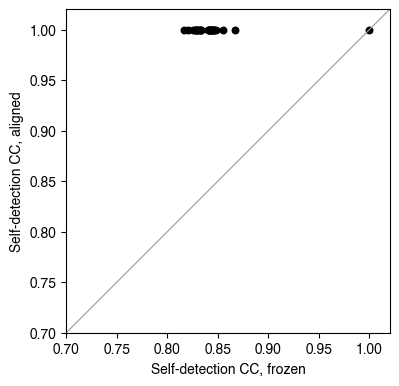

In [3]:
rows = []
for k in RUNS:
    r = raw[k]
    for ti, e in enumerate(ev):
        o = tpl.set_index('event_id').loc[e, 'origin_time_UTC']
        h = r[(r.template_idx == ti) & ((r.origin_utc - o).abs().dt.total_seconds() <= 3)]
        rows.append(dict(run=k, event_id=e, self_cc=h.cc.max() if len(h) else np.nan))
selfcc = pd.DataFrame(rows).pivot(index='event_id', columns='run', values='self_cc')
print('self-detected templates:', {k: int(selfcc[k].notna().sum()) for k in RUNS}, 'of', len(ev))
display(selfcc.describe().loc[['min', '50%', 'max']].round(3))
for k in RUNS:
    f = f'{DL}/logs/fmf_{k}_check_306.log'
    if os.path.exists(f): print(k, 'check day:', [l.strip() for l in open(f) if 'self-detection' in l][:1])
fig, ax = plt.subplots(figsize=(4.4, 4.2))
ax.scatter(selfcc.frozen, selfcc.aligned, s=22, color='black'); ax.plot([0.7, 1.02], [0.7, 1.02], color='0.6', lw=0.8)
ax.set_xlabel('Self-detection CC, frozen'); ax.set_ylabel('Self-detection CC, aligned'); ax.set_xlim(0.7, 1.02); ax.set_ylim(0.7, 1.02); ax.set_aspect('equal'); plt.show()

## 3. Detections over the period

,raw_hits,hits_after_floor,detections,reference,new,new_in_swarm_window,new_outside_swarm_window
frozen,2880,2540,179,28,151,150,1
aligned,3075,2726,187,28,159,158,1


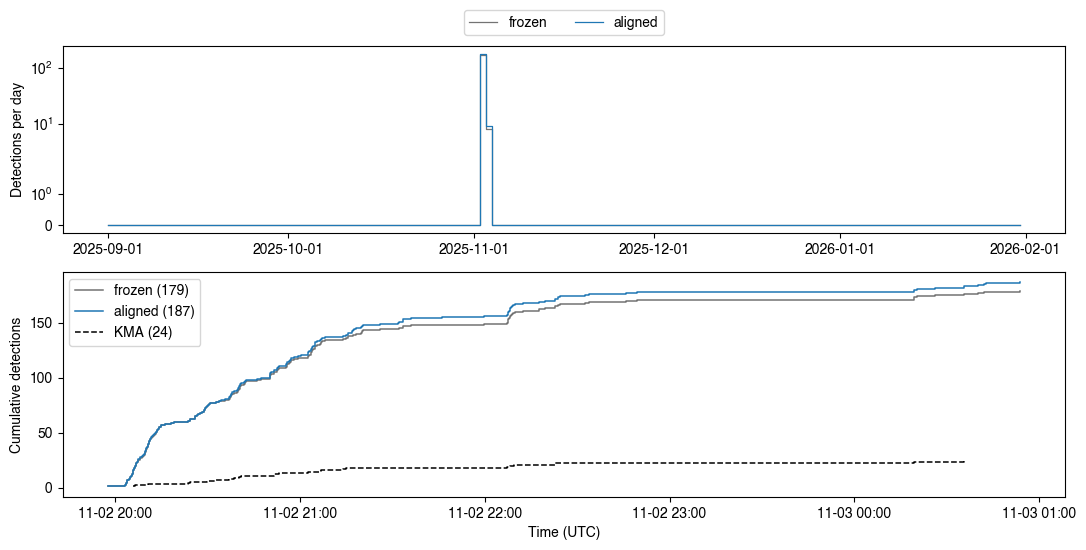

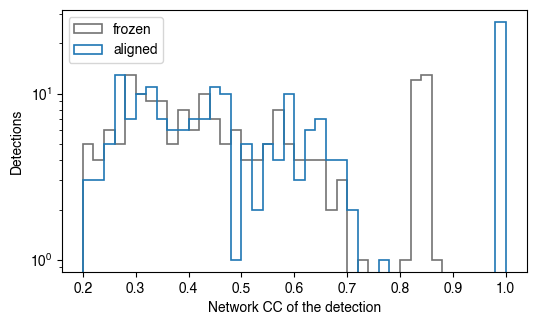

In [4]:
def gated(r): return r[(r.cc >= FLOOR) & (r.n_present >= MIN_STA)]
cnt = pd.DataFrame({k: dict(raw_hits=len(raw[k]), hits_after_floor=len(gated(raw[k])), detections=len(cat[k]), reference=int(cat[k].is_reference.sum()),
                            new=int(cat[k].is_new.sum()), new_in_swarm_window=int((cat[k].is_new & cat[k].origin.between(SW0, SW1)).sum()),
                            new_outside_swarm_window=int((cat[k].is_new & ~cat[k].origin.between(SW0, SW1)).sum())) for k in RUNS}).T
display(cnt)
days = pd.date_range(T0, T1 - pd.Timedelta(days=1))
fig, ax = plt.subplots(2, 1, figsize=(11, 5.6), gridspec_kw=dict(height_ratios=[1, 1.2]))
for k in RUNS:
    c = cat[k]; n = c.groupby(c.origin.dt.normalize()).size().reindex(days, fill_value=0)
    ax[0].step(days, n.values, where='post', color=COL[k], lw=0.9, label=k)
    s = c[c.origin.between(SW0 - pd.Timedelta(hours=1), SW1 + pd.Timedelta(hours=2))].sort_values('origin')
    ax[1].step(s.origin, np.arange(1, len(s) + 1), where='post', color=COL[k], lw=1.1, label=f'{k} ({len(s)})')
kk = kma[kma.origin_time_UTC.between(SW0 - pd.Timedelta(hours=1), SW1 + pd.Timedelta(hours=2))].sort_values('origin_time_UTC')
ax[1].step(kk.origin_time_UTC, np.arange(1, len(kk) + 1), where='post', color='black', lw=1.1, ls='--', label=f'KMA ({len(kk)})')
ax[0].set_yscale('symlog'); ax[0].set_ylabel('Detections per day'); ax[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
ax[1].set_ylabel('Cumulative detections'); ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M')); ax[1].set_xlabel('Time (UTC)')
ax[0].legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=True); ax[1].legend(loc='upper left', frameon=True)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(6, 3.4))
for k in RUNS: ax.hist(cat[k].cc, bins=np.arange(0.2, 1.01, 0.02), histtype='step', color=COL[k], lw=1.2, label=k)
ax.set_xlabel('Network CC of the detection'); ax.set_ylabel('Detections'); ax.set_yscale('log'); ax.legend(frameon=True); plt.show()

## 4. Frozen against aligned, detection by detection
Detections of the two runs are paired when their origins are within 2 s.

common 174; only frozen 5; only aligned 13
CC ratio aligned / frozen for common detections: median 1.108 (5-95 %: 0.923-1.255)
only-frozen detections: CC median 0.294, n_present median 9; only-aligned detections: CC median 0.261, n_present median 10


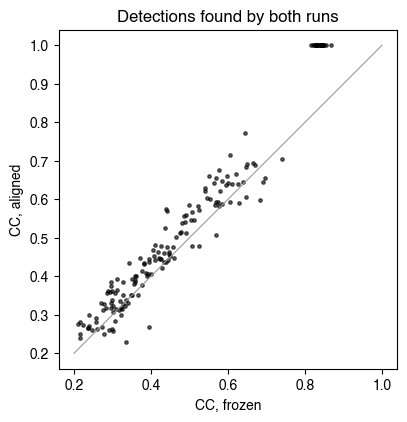

In [5]:
a, b = cat['frozen'].sort_values('origin').reset_index(drop=True), cat['aligned'].sort_values('origin').reset_index(drop=True)
tb = b.origin.values.astype('datetime64[ns]').astype('int64') / 1e9
def nearest(t):
    i = np.clip(np.searchsorted(tb, t), 1, len(tb) - 1); j = np.where(np.abs(tb[i - 1] - t) <= np.abs(tb[i] - t), i - 1, i); return j, np.abs(tb[j] - t)
j, d = nearest(a.origin.values.astype('datetime64[ns]').astype('int64') / 1e9)
pair = d <= 2.0
common = pd.DataFrame(dict(origin=a.origin[pair].values, cc_frozen=a.cc[pair].values, cc_aligned=b.cc.values[j[pair]], new_frozen=a.is_new[pair].values, new_aligned=b.is_new.values[j[pair]]))
only_f = a[~pair]; only_a = b.drop(index=np.unique(j[pair]))
print(f'common {len(common)}; only frozen {len(only_f)}; only aligned {len(only_a)}')
print(f'CC ratio aligned / frozen for common detections: median {np.median(common.cc_aligned / common.cc_frozen):.3f} (5-95 %: {np.percentile(common.cc_aligned / common.cc_frozen, 5):.3f}-{np.percentile(common.cc_aligned / common.cc_frozen, 95):.3f})')
print('only-frozen detections: CC median %.3f, n_present median %.0f; only-aligned detections: CC median %.3f, n_present median %.0f' % (only_f.cc.median(), only_f.n_present.median(), only_a.cc.median(), only_a.n_present.median()))
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.scatter(common.cc_frozen, common.cc_aligned, s=6, color='black', alpha=0.6); ax.plot([0.2, 1], [0.2, 1], color='0.6', lw=0.8)
ax.set_xlabel('CC, frozen'); ax.set_ylabel('CC, aligned'); ax.set_aspect('equal'); ax.set_title('Detections found by both runs'); plt.show()

## 5. The 24 KMA swarm events

In [6]:
kr = []
for k in RUNS:
    c = cat[k]; t = c.origin.values.astype('datetime64[ns]').astype('int64') / 1e9
    for r in kma.itertuples():
        dd = np.abs(t - r.origin_time_UTC.value / 1e9); i = int(np.argmin(dd))
        kr.append(dict(run=k, event_id=r.event_id, ML=r.ML, found=dd[i] <= GROUP_S, offset_s=round(dd[i], 2), cc=c.cc.iloc[i], is_reference=bool(c.is_reference.iloc[i])))
kr = pd.DataFrame(kr)
display(kr.groupby('run').agg(found=('found', 'sum'), as_reference=('is_reference', lambda v: int((v & kr.loc[v.index, 'found']).sum())), median_cc=('cc', 'median')))
print('KMA events not found:', {k: list(kr[(kr.run == k) & ~kr.found].event_id) for k in RUNS})

,found,as_reference,median_cc
run,,,
aligned,24,22,0.999985
frozen,24,22,0.836822


KMA events not found: {'frozen': [], 'aligned': []}


## 6. Coda-template screen (decision D13)
Some templates belong to events that came a few seconds after a larger event. Their correlation windows then contain that event's coda, so they re-detect every comparable large event at the same delay. Haenam found six such templates by exactly that repeat-at-delay signature; at Imsil the swarm events are 8–48 s apart.

The check, for each template:
1. List the larger or equal events (by phase count) inside the Imsil box within 40 s before the template's own event.
2. Count the template's hits that fall at that same delay, within 0.5 s, after any other comparable event.

Templates with two or more such repeats are candidates for exclusion. This section screens them; the exclusion is your decision.

In [7]:
box = dl[dl.in_imsil_box].sort_values('time').reset_index(drop=True)
def screen(k):
    r = gated(raw[k]); out = []
    for ti, e in enumerate(ev):
        me = box[box.event_id == e]
        if me.empty: continue
        tT, nT = me.time.iloc[0], int(me.num.iloc[0])
        prev = box[(box.time < tT - pd.Timedelta(seconds=1)) & (box.time >= tT - pd.Timedelta(seconds=40)) & (box.num >= nT)]
        hits = r[r.template_idx == ti].origin_utc
        for L in prev.itertuples():
            delta = (tT - L.time).total_seconds()
            big = box[(box.num >= nT) & (box.event_id != L.event_id) & (box.event_id != e)].time
            tgt = (big + pd.Timedelta(seconds=delta)).values.astype('datetime64[ns]').astype('int64') / 1e9
            th = hits.values.astype('datetime64[ns]').astype('int64') / 1e9
            rep = int(sum(np.min(np.abs(tgt - h)) <= 0.5 for h in th)) if len(tgt) and len(th) else 0
            out.append(dict(run=k, cuspid=400000 + ti, event_id=e, own_phases=nT, preceding_event=L.event_id, preceding_phases=int(L.num), delay_s=round(delta, 2), template_hits=len(th), repeats_at_delay=rep))
    return pd.DataFrame(out)
scr = pd.concat([screen(k) for k in RUNS], ignore_index=True)
cand = scr[scr.repeats_at_delay >= 2]
display(scr.sort_values(['run', 'repeats_at_delay'], ascending=[True, False]).groupby('run').head(10))
print('D13 candidates (>= 2 repeats at the delay):', {k: sorted(set(cand[cand.run == k].event_id)) for k in RUNS})

,run,cuspid,event_id,own_phases,preceding_event,preceding_phases,delay_s,template_hits,repeats_at_delay
2,aligned,400010,20251102203705,19,20251102203649,35,15.75,102,0
3,aligned,400021,20251102220723,13,20251102220714,33,8.16,0,0
0,frozen,400010,20251102203705,19,20251102203649,35,15.75,102,0
1,frozen,400021,20251102220723,13,20251102220714,33,8.16,0,0


D13 candidates (>= 2 repeats at the delay): {'frozen': [], 'aligned': []}


## 7. New detections outside the swarm window
These are the detections that no 25 m reference origin explains, outside 2025-11-02 20:00 – 11-03 01:00 UTC. They are candidate events before and after the swarm.

In [8]:
for k in RUNS:
    nn = cat[k][cat[k].is_new & ~cat[k].origin.between(SW0, SW1)].sort_values('origin')
    print(f'{k}: {len(nn)} new detections outside the swarm window; by month {nn.origin.dt.to_period("M").value_counts().sort_index().to_dict()}')
    display(nn[['origin', 'template_cuspid', 'cc', 'n_present', 'n_templates']].head(30).round(3))

frozen: 1 new detections outside the swarm window; by month {Period('2025-11', 'M'): 1}


,origin,template_cuspid,cc,n_present,n_templates
0,2025-11-02 19:57:38.092002,400005,0.326,7,6


aligned: 1 new detections outside the swarm window; by month {Period('2025-11', 'M'): 1}


,origin,template_cuspid,cc,n_present,n_templates
0,2025-11-02 19:57:38.092002,400005,0.316,7,3


## Comprehensive summary

In [9]:
summary = pd.DataFrame([
    ('Templates / stations', f'{len(ev)} / {len(sta)} (S on Z at {", ".join(sta.station[sta.horizontals == 0])})'),
    ('Self-detection CC, median (min): frozen / aligned', f'{selfcc.frozen.median():.3f} ({selfcc.frozen.min():.3f}) / {selfcc.aligned.median():.3f} ({selfcc.aligned.min():.3f})'),
    ('Merged detections: frozen / aligned', f'{cnt.loc["frozen", "detections"]} / {cnt.loc["aligned", "detections"]}'),
    ('Reference / new: frozen', f'{cnt.loc["frozen", "reference"]} / {cnt.loc["frozen", "new"]}'),
    ('Reference / new: aligned', f'{cnt.loc["aligned", "reference"]} / {cnt.loc["aligned", "new"]}'),
    ('New outside the swarm window: frozen / aligned', f'{cnt.loc["frozen", "new_outside_swarm_window"]} / {cnt.loc["aligned", "new_outside_swarm_window"]}'),
    ('Common / only frozen / only aligned', f'{len(common)} / {len(only_f)} / {len(only_a)}'),
    ('CC ratio aligned / frozen (common, median)', f'{np.median(common.cc_aligned / common.cc_frozen):.3f}'),
    ('KMA events found: frozen / aligned', ' / '.join(str(int(kr[kr.run == k].found.sum())) for k in RUNS) + ' of 24'),
    ('D13 candidates (frozen; aligned)', '; '.join(', '.join(sorted(set(cand[cand.run == k].event_id))) or 'none' for k in RUNS)),
], columns=['quantity', 'value'])
display(summary)
print('Decisions this notebook informs (user): D20 - frozen or aligned FMF code; D13 - exclusion of coda templates.')

,quantity,value
0,Templates / stations,"28 / 22 (S on Z at NAWB, KWJ2)"
1,"Self-detection CC, median (min): frozen / aligned",0.841 (0.817) / 1.000 (1.000)
2,Merged detections: frozen / aligned,179 / 187
3,Reference / new: frozen,28 / 151
4,Reference / new: aligned,28 / 159
5,New outside the swarm window: frozen / aligned,1 / 1
6,Common / only frozen / only aligned,174 / 5 / 13
7,"CC ratio aligned / frozen (common, median)",1.108
8,KMA events found: frozen / aligned,24 / 24 of 24
9,D13 candidates (frozen; aligned),none; none


Decisions this notebook informs (user): D20 - frozen or aligned FMF code; D13 - exclusion of coda templates.
